# Phase 1 · 02 · Balanced subset

**Goal:** select exactly the samples the paper's classifier was trained and tested on: CRC and control samples, balanced inside every study.

**What this notebook shows**
- Why the classes are balanced at all, and why it has to happen inside each study.
- The authors' balancing function rewritten in Python and tested on a toy table.
- That our version picks the same number of samples per study as the paper, and why the exact samples can only come from the paper's own flag.

## Setup

The helpers below are copied from notebook 01, so this notebook runs on its own.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

SEED = 2000
print("SEED =", SEED)

SEED = 2000


In [2]:
def find_project_root() -> Path:
    """Walk up from the current folder until we find the one that holds requirements.txt."""
    folder = Path.cwd()
    while not (folder / "requirements.txt").exists():
        if folder.parent == folder:
            raise FileNotFoundError("Could not find the project root (no requirements.txt above this folder).")
        folder = folder.parent
    return folder


def load_raw_tables(root: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Return (metadata, relab), both indexed by Sample_ID and in the same row order."""
    raw = root / "data" / "raw"
    metadata = pd.read_csv(raw / "Metadata.all.samples.tsv", sep="\t", index_col="Sample_ID", dtype={"Sample_ID": str})
    genus_by_sample = pd.read_csv(raw / "Relab.all.samples.tsv", sep="\t", index_col=0)
    relab = genus_by_sample.T
    if set(relab.index) != set(metadata.index):
        raise ValueError("The two tables do not contain the same samples.")
    relab = relab.loc[metadata.index]
    return metadata, relab


PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES = PROJECT_ROOT / "results" / "figures"
NOTEBOOK_PREFIX = "p1_02"
figure_number = 0


def show_figure(fig: plt.Figure, name: str, caption: str) -> None:
    global figure_number
    figure_number += 1
    FIGURES.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES / f"{NOTEBOOK_PREFIX}_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    display(Markdown(f"**Figure {figure_number}.** {caption}"))

This notebook only needs the metadata. The abundance table is loaded again in notebook 03.

In [3]:
metadata, _ = load_raw_tables(PROJECT_ROOT)
crc_ctr = metadata[metadata["Condition"].isin(["CRC", "CTR"])]
print(f"{len(crc_ctr):,} CRC and control samples out of {len(metadata):,}")

6,779 CRC and control samples out of 8,330


## 1. Why balance, and why inside each study?

**Balance.** If 80% of the training samples were cancer, a model could score 80% accuracy by always answering "cancer". With equal numbers of CRC and controls, the only way to do well is to actually find the signal. The paper balances both training and test sets.

**Inside each study.** Suppose study A is 90% cancer and study B is 90% controls. Because each study has its own measurement quirks, the model could learn "looks like study A, so cancer" without learning anything about cancer. Balancing every study to 50/50 removes that shortcut: knowing the study tells the model nothing about the label.

The authors do this with `balance_data_by_groups` in their `utils.R`: in every study, count the CRC and control samples, take the smaller number, and randomly keep that many of each class.

## 2. The balancing function in Python

In [4]:
def balance_per_cohort(metadata: pd.DataFrame, seed: int) -> pd.DataFrame:
    """In every cohort, randomly keep the same number of CRC and CTR samples (the size of the smaller class)."""
    rng = np.random.default_rng(seed)
    kept = []
    for cohort, samples in metadata.groupby("Cohort"):
        counts = samples["Condition"].value_counts()
        n_per_class = min(counts.get("CRC", 0), counts.get("CTR", 0))
        for condition in ["CRC", "CTR"]:
            candidates = samples.index[samples["Condition"] == condition]
            kept.extend(rng.choice(candidates, size=n_per_class, replace=False))
    return metadata.loc[kept]

A toy table first. Study A has 3 CRC and 2 controls, so it keeps 2 of each. Study B has only CRC samples, so the smaller class has 0 samples and the whole study is dropped. Keeping it would put cancer-only data back in.

In [5]:
toy = pd.DataFrame(
    {"Cohort": ["A"] * 5 + ["B"] * 3, "Condition": ["CRC"] * 3 + ["CTR"] * 2 + ["CRC"] * 3},
    index=[f"s{i}" for i in range(8)],
)
toy_balanced = balance_per_cohort(toy, seed=SEED)
toy_balanced

,Cohort,Condition
s1,A,CRC
s0,A,CRC
s4,A,CTR
s3,A,CTR


## 3. Compare with the paper's balanced set

The paper's balanced samples are marked in the metadata column `Used_in_balanced_model`. We compare how many samples per study and class each version keeps.

Our version can match the *counts* but not the *exact samples*. Picking samples at random depends on the random number generator, and R and Python use different ones. Even with the same seed (2000) they draw different samples. So from here on we use the paper's flag, which gives us exactly their samples.

In [6]:
flagged = crc_ctr[crc_ctr["Used_in_balanced_model"] == "Yes"]
ours = balance_per_cohort(crc_ctr, seed=SEED).groupby(["Cohort", "Condition"]).size()
theirs = flagged.groupby(["Cohort", "Condition"]).size()

comparison = pd.DataFrame({"ours": ours, "paper": theirs}).unstack("Condition")
comparison

ours      paper     
Condition        CRC  CTR   CRC  CTR
Cohort                              
BaxterNT_2016    120  120   120  120
DengX_2018        17   17    17   17
DuX_2022          27   27    27   27
FengQ_2015        46   46    46   46
GaoR_2021         16   16    16   16
HanniganGD_2018   16   16    16   16
KonishiY_2022    437  437   437  437
LiuNN_2022        79   79    79   79
OkumuraS_2021    513  513   513  513
TernesD_2022      46   46    46   46
ThomasAM_2019_1   24   24    24   24
ThomasAM_2019_2   28   28    28   28
UchinoY_2021      51   51    51   51
VogtmannE_2016    52   52    52   52
WirbelJ_2019      60   60    60   60
XuJ_2022          30   30    30   30
YachidaS_2019    249  249   249  249
YangJ_2019        95   95    95   95
YangTW_2019       37   37    37   37
YangY_2021a      351  351   351  351
YangY_2021b      123  123   123  123
YangY_2021c       99   99    99   99
YoungC1_2021      40   40    40   40
YoungC2_2021     303  303   303  303
YuJ_2017          54   54    54   54
ZellerG_2014      52   52    52   52
ZhouZ_2022        18   18    18   18

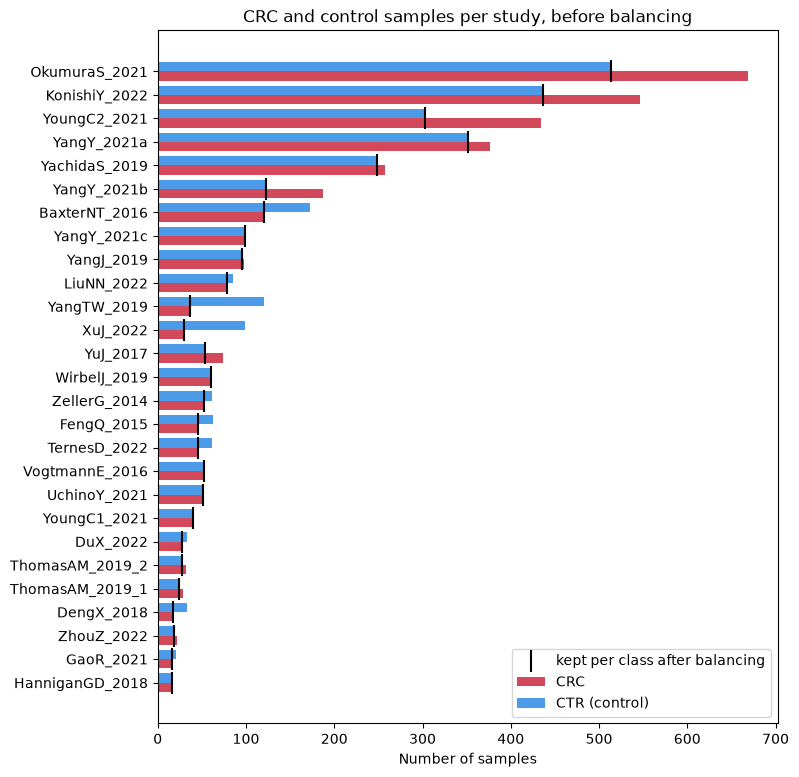

**Figure 1.** Before balancing there are 3,516 CRC and 3,263 control samples. The largest gap is in OkumuraS_2021 (669 CRC, 513 controls), and the most lopsided study is XuJ_2022, where only 23% of samples are CRC. Keeping the smaller class size in every study (black marks) leaves 5,966 samples, 2,983 per class, and drops 813 samples (12%).

In [7]:
counts_before = crc_ctr.groupby(["Cohort", "Condition"]).size().unstack("Condition", fill_value=0)
counts_before = counts_before.loc[counts_before.sum(axis=1).sort_values().index]
kept_per_class = flagged.groupby("Cohort").size().div(2).reindex(counts_before.index)

fig, ax = plt.subplots(figsize=(8, 9))
positions = np.arange(len(counts_before))
ax.barh(positions - 0.2, counts_before["CRC"], height=0.4, color="#D1495B", label="CRC")
ax.barh(positions + 0.2, counts_before["CTR"], height=0.4, color="#4C9BE8", label="CTR (control)")
ax.scatter(kept_per_class, positions, marker="|", s=250, color="black", zorder=3, label="kept per class after balancing")
ax.set_yticks(positions, counts_before.index)
ax.set_xlabel("Number of samples")
ax.set_title("CRC and control samples per study, before balancing")
ax.legend(loc="lower right")

largest_gap = (counts_before["CRC"] - counts_before["CTR"]).abs().idxmax()
crc_share = counts_before["CRC"] / counts_before.sum(axis=1)
most_lopsided = (crc_share - 0.5).abs().idxmax()
dropped = len(crc_ctr) - len(flagged)
show_figure(
    fig,
    "balance_per_cohort",
    f"Before balancing there are {counts_before['CRC'].sum():,} CRC and {counts_before['CTR'].sum():,} control samples. "
    f"The largest gap is in {largest_gap} ({counts_before.loc[largest_gap, 'CRC']} CRC, {counts_before.loc[largest_gap, 'CTR']} controls), "
    f"and the most lopsided study is {most_lopsided}, where only {crc_share[most_lopsided]:.0%} of samples are CRC. Keeping the smaller class size in every study (black marks) "
    f"leaves {len(flagged):,} samples, {len(flagged) // 2:,} per class, and drops {dropped:,} samples ({dropped / len(crc_ctr):.0%}).",
)

## 4. Save the balanced sample list

Notebook 03 builds the feature table from this list.

In [8]:
PROCESSED.mkdir(parents=True, exist_ok=True)
balanced_samples = flagged[["Cohort", "Assay", "Condition"]].reset_index()
balanced_samples.to_csv(PROCESSED / "balanced_samples.csv", index=False)
print(f"Saved {len(balanced_samples):,} rows to data/processed/balanced_samples.csv")

Saved 5,966 rows to data/processed/balanced_samples.csv


## 5. Checks

In [9]:
toy = pd.DataFrame({"Cohort": ["A"]*5 + ["B"]*3, "Condition": ["CRC"]*3 + ["CTR"]*2 + ["CRC"]*3},
                   index=[f"s{i}" for i in range(8)])
toy_balanced = balance_per_cohort(toy, seed=SEED)
assert toy_balanced.groupby(["Cohort", "Condition"]).size().to_dict() == {("A", "CRC"): 2, ("A", "CTR"): 2}

ours = balance_per_cohort(crc_ctr, seed=SEED).groupby(["Cohort", "Condition"]).size()
theirs = flagged.groupby(["Cohort", "Condition"]).size()
assert ours.equals(theirs)
assert len(flagged) == 5966
assert (flagged["Condition"] == "CRC").sum() == 2983
assert (flagged.groupby("Cohort")["Condition"].value_counts().unstack().nunique(axis=1) == 1).all()
assert len(pd.read_csv(PROCESSED / "balanced_samples.csv")) == 5966
print("All checks passed.")

All checks passed.


## What we learned

- Balancing per study removes a shortcut: after it, knowing which study a sample came from says nothing about its label.
- A study with only one class would be dropped entirely. All 27 studies here have both classes, so all 27 stay.
- Our Python version keeps exactly the same number of samples per study and class as the paper: 5,966 in total, 2,983 CRC and 2,983 controls, with 813 samples dropped.
- The exact samples can't be reproduced, because R and Python draw different random numbers. From here on we use the paper's `Used_in_balanced_model` flag, saved in `data/processed/balanced_samples.csv`.